<a href="https://colab.research.google.com/github/dudechego/Python-Deep-Learning-Projects/blob/main/Cat_v_Dog_Classifier_CNN_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install streamlit
!pip install pyngrok
!pip install kagglehub

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 82.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 89.7 MB/s eta 0:00:00


In [ ]:

import pandas as pd
import requests
import kagglehub
import random
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import streamlit as st
from pyngrok import ngrok
import torch

from tqdm.auto import tqdm
from torch import nn, optim
from torchvision.utils import make_grid
from torch.utils.data import DataLoader, Dataset
from torchvision.transforms import transforms, v2
from PIL import Image

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cpu'

In [ ]:
#Download the dataset
path = kagglehub.dataset_download("karakaggle/kaggle-cat-vs-dog-dataset")
print("Dataset Path: ", path)

100%|██████████| 787M/787M [00:10<00:00, 81.4MB/s]

Extracting files...


Dataset Path:  /root/.cache/kagglehub/datasets/karakaggle/kaggle-cat-vs-dog-dataset/versions/1


In [ ]:
#pet_url = "/kaggle/input/kaggle-cat-vs-dog-dataset/kagglecatsanddogs_3367a/PetImages"
pet_url = "/root/.cache/kagglehub/datasets/karakaggle/kaggle-cat-vs-dog-dataset/versions/1/kagglecatsanddogs_3367a/PetImages"

labels_list = []
pets_list = []
path_img = [".png", ".jpg", ".jpeg"]

for pet in os.listdir(pet_url):
    for pets in os.listdir(f"{pet_url}/{pet}"):
        if pets.endswith((".png", ".jpeg", ".jpg")):
            pets_list.append(f"{pet_url}/{pet}/{pets}")

for label in pets_list:
    #print(label)
    if "Dog" in label:
        labels_list.append(0)
    elif "Cat" in label:
        labels_list.append(1)

print(len(pets_list))
print(len(labels_list))

print(pets_list[-6:])
print(labels_list[-6:])

24959
24959
['/root/.cache/kagglehub/datasets/karakaggle/kaggle-cat-vs-dog-dataset/versions/1/kagglecatsanddogs_3367a/PetImages/Dog/12021.jpg', '/root/.cache/kagglehub/datasets/karakaggle/kaggle-cat-vs-dog-dataset/versions/1/kagglecatsanddogs_3367a/PetImages/Dog/4219.jpg', '/root/.cache/kagglehub/datasets/karakaggle/kaggle-cat-vs-dog-dataset/versions/1/kagglecatsanddogs_3367a/PetImages/Dog/2173.jpg', '/root/.cache/kagglehub/datasets/karakaggle/kaggle-cat-vs-dog-dataset/versions/1/kagglecatsanddogs_3367a/PetImages/Dog/8894.jpg', '/root/.cache/kagglehub/datasets/karakaggle/kaggle-cat-vs-dog-dataset/versions/1/kagglecatsanddogs_3367a/PetImages/Dog/5053.jpg', '/root/.cache/kagglehub/datasets/karakaggle/kaggle-cat-vs-dog-dataset/versions/1/kagglecatsanddogs_3367a/PetImages/Dog/1445.jpg']
[0, 0, 0, 0, 0, 0]


In [ ]:
zip_list = zip(pets_list, labels_list)
#print(random.shuffle(zip_list))

In [ ]:
#random.shuffle(labels_list)

In [ ]:
#Create Dataframe
pet_df = pd.DataFrame(zip_list, columns=["Image", "Label"])
pet_df.head()

,Image,Label
0,/root/.cache/kagglehub/datasets/karakaggle/kag...,1
1,/root/.cache/kagglehub/datasets/karakaggle/kag...,1
2,/root/.cache/kagglehub/datasets/karakaggle/kag...,1
3,/root/.cache/kagglehub/datasets/karakaggle/kag...,1
4,/root/.cache/kagglehub/datasets/karakaggle/kag...,1


In [ ]:
new_pets = []
for x in range(len(pets_list)):
    new_pets.append(pet_df.iloc[x])

print(new_pets[0])
print(len(new_pets))
random.shuffle(new_pets)
#print(new_pets[0])

for x in range(len(pets_list)):
    pet_df.iloc[x] = new_pets[x]

Image    /root/.cache/kagglehub/datasets/karakaggle/kag...
Label                                                    1
Name: 0, dtype: object
24959


In [ ]:
pet_df.head()

,Image,Label
0,/root/.cache/kagglehub/datasets/karakaggle/kag...,0
1,/root/.cache/kagglehub/datasets/karakaggle/kag...,0
2,/root/.cache/kagglehub/datasets/karakaggle/kag...,1
3,/root/.cache/kagglehub/datasets/karakaggle/kag...,0
4,/root/.cache/kagglehub/datasets/karakaggle/kag...,0


In [ ]:
pet_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24959 entries, 0 to 24958
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Image   24959 non-null  object
 1   Label   24959 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 390.1+ KB


In [ ]:
print(pet_df.iloc[6]["Image"])
print(pet_df.iloc[6]["Label"])

/root/.cache/kagglehub/datasets/karakaggle/kaggle-cat-vs-dog-dataset/versions/1/kagglecatsanddogs_3367a/PetImages/Dog/9100.jpg
0


In [ ]:
#Dog = 0
#Cat = 1

In [ ]:
#Hyperparameters
lr = 0.01
EPOCHS = 10
image_size = 256
batch_size = 16

In [ ]:
##Create Dataset Class
class CustomDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        super().__init__()

        self.dataframe = dataframe
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        item = self.dataframe.iloc[idx]

        image_path = item.iloc[0]
        label_path = item.iloc[1]

        #Open Image
        image = Image.open(image_path).convert("RGB")
        label = torch.tensor(label_path, dtype=torch.float32)

        if self.transform:
            image_transform = self.transform(image)

        return image_transform, label

In [ ]:
#Transform Images
train_transform = v2.Compose([
v2.ToTensor(),
v2.Resize((image_size, image_size)),
v2.RandomRotation(50),
v2.RandomHorizontalFlip(0.2),
])

test_transform = v2.Compose([
v2.ToTensor(),
v2.Resize((image_size, image_size)),
v2.RandomRotation(50),
v2.RandomHorizontalFlip(0.2),
])

/usr/local/lib/python3.13/dist-packages/torchvision/transforms/v2/_deprecated.py:42: UserWarning: The transform `ToTensor()` is deprecated and will be removed in a future release. Instead, please use `v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])`.Output is equivalent up to float precision.
  warnings.warn(


In [ ]:
train_df = pet_df.sample(frac=0.75)
test_df = pet_df.drop(train_df.index)
val_df = test_df.sample(frac=0.5)
test_df = test_df.drop(val_df.index)

In [ ]:
print(train_df.shape)
print(test_df.shape)
print(val_df.shape)

(18719, 2)
(3120, 2)
(3120, 2)


In [ ]:
#Create Datasets
train_data = CustomDataset(train_df, train_transform)
test_data = CustomDataset(test_df, test_transform)
val_data = CustomDataset(val_df, test_transform)

In [ ]:
print(train_data[10][0].shape)

torch.Size([3, 256, 256])


In [ ]:
#Dataloaders
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_data, batch_size=batch_size)
val_loader = DataLoader(val_data, batch_size=batch_size)

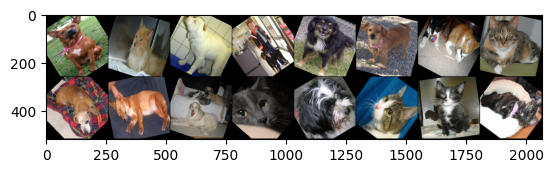

In [ ]:
#Plot Data
images, labels = next(iter(train_loader))
plot_images = make_grid(images)
plt.imshow(plot_images.cpu().numpy().transpose((1,2,0)))

In [ ]:
##Create ConvBlock
class ConvBlock(nn.Module):
    def __init__(self, input_shape, output_shape):
        super().__init__()

        self.layer = nn.Sequential(
            nn.Conv2d(input_shape, output_shape, kernel_size=4, stride=1, padding=1),
            nn.BatchNorm2d(output_shape),
            nn.ReLU(),
            nn.Conv2d(output_shape, output_shape, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(output_shape),
            nn.ReLU(),
        )

    def forward(self, x):
        return self.layer(x)

In [ ]:
##Create CNN Model
class CNN(nn.Module):
    def __init__(self):
        super().__init__()

        #Sequential Layer
        self.layer = nn.Sequential(
            #Input: (32, 3, 256, 256)
            ConvBlock(3, 16), #(32, 3, 255, 255)
            nn.MaxPool2d(2,2), #(32, 16, 127, 127)

            #Input: (32, 16, 127, 127)
            ConvBlock(16, 32), #(32, 32, 126, 126)
            nn.MaxPool2d(2,2), #(32, 32, 63, 63)

            #Input: (32, 32, 63, 63)
            ConvBlock(32, 64), #(32, 64, 62, 62)
            nn.MaxPool2d(2,2), #(32, 64, 31, 31)

            #Input: (32, 64, 31, 31)
            ConvBlock(64, 128), #(32, 128, 30, 30)
            nn.MaxPool2d(2,2), #(32, 128, 15, 15)

            #Flatten Output
            nn.Flatten(),

            #Linear Layer
            nn.Linear(128*15*15, 256),

            nn.Linear(256, 128),

            nn.Linear(128, 64),

            nn.Linear(64, 1),

        )


    def forward(self, x):
        return self.layer(x)

In [ ]:

model = CNN().to(device)
model

CNN(
  (layer): Sequential(
    (0): ConvBlock(
      (layer): Sequential(
        (0): Conv2d(3, 16, kernel_size=(4, 4), stride=(1, 1), padding=(1, 1))
        (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU()
        (3): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (4): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (5): ReLU()
      )
    )
    (1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (2): ConvBlock(
      (layer): Sequential(
        (0): Conv2d(16, 32, kernel_size=(4, 4), stride=(1, 1), padding=(1, 1))
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU()
        (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (5): ReLU()
      )
    )

In [ ]:

loss_fn = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=lr)
lr_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

In [ ]:
#Test Model
model.eval()
with torch.inference_mode():
    test_loss = 0
    for image, label in test_loader:
        image, label = image.to(device), label.to(device)

        #Forward Pass
        test_outputs = model(image)

        #Loss Calculation
        loss = loss_fn(test_outputs, label.unsqueeze(1))

        test_loss += loss.item()
    test_loss /= len(test_loader)

In [ ]:

print(test_loss)

0.694102079134721


In [ ]:
#Train Model
torch.manual_seed(2)
torch.cuda.manual_seed(2)

model.train()
for epoch in tqdm(range(EPOCHS)):
    train_loss = 0
    test_loss = 0
    for image, label in train_loader:
        image, label = image.to(device), label.to(device)

        optimizer.zero_grad()

        #Forward Pass
        train_outputs = model(image)

        #Loss Calculation
        loss = loss_fn(train_outputs, label.unsqueeze(1))

        loss.backward()
        optimizer.step()

        train_loss += loss.item()
    train_loss /= len(train_loader)

    #Test Model
    model.eval()
    with torch.inference_mode():
        test_loss = 0
        for image, label in test_loader:
            image, label = image.to(device), label.to(device)

            #Forward Pass
            test_outputs = model(image)

            #Loss Calculation
            loss = loss_fn(test_outputs, label.unsqueeze(1))

            test_loss += loss.item()
        test_loss /= len(test_loader)

    lr_scheduler.step()
    if epoch % 3 == 0:
        print(f"Epoch: {epoch} | Train Loss: {train_loss:.6f} | Test Loss: {test_loss:.6f} ")

Appending to app.py


In [ ]:
#Test Model
model.eval()
with torch.inference_mode():
    test_loss = 0
    for image, label in test_loader:
        image, label = image.to(device), label.to(device)

        #Forward Pass
        test_outputs = model(image)

        #Loss Calculation
        loss = loss_fn(test_outputs, label.unsqueeze(1))

        test_loss += loss.item()
    test_loss /= len(test_loader)

Appending to app.py


In [ ]:
print(test_loss)

In [ ]:
#Save Model
torch.save(model.state_dict(), "cnn_model.pth")
torch.save(model, "cnn_model.pt")

Appending to app.py


In [ ]:
#Reload Model
new_model = CNN().to(device)
new_model.load_state_dict(torch.load("cnn_model.pth"))
new_model

Appending to app.py


In [ ]:
#Make a Prediction
image_url = ""
response = requests.get(image_url)
image_path = BytesIO(response.content)
image = Image.open(image_path).convert("RGB")
image

In [ ]:
sample_img = train_data[0][0]

#sample_img

In [ ]:
#Transform Image
image_tensor = train_transform(sample_img)
image_tensor = image_tensor.to(device)
print(image_tensor.shape)

torch.Size([3, 256, 256])


In [ ]:
!ngrok config add-authtoken 31EegdOBZkg31mSkHEssCa8ig1Z_2bFH1HqC2ifJGo5vb4Poy

Authtoken saved to configuration file: /root/.config/ngrok/ngrok.yml


In [ ]:
#Run our Permanent Ngrok Tunnel
from pyngrok import ngrok

ngrok.kill()
os.system("streamlit run app.py --server.port 8501 &")
public_url = ngrok.connect(8501, proto="http")
print("Link: ", public_url)

Link:  NgrokTunnel: "https://a54f-136-70-242-39.ngrok-free.app" -> "http://localhost:8501"


In [ ]:
# Instantiate a new model and load the saved state dict
#new_model = CNN().to(device)
#new_model.load_state_dict(torch.load("cnn_model.pth"))

new_model.eval()

# Pass Image To Model
with torch.inference_mode():
    # Ensure input tensor has a batch dimension (1, C, H, W)
    if len(image_tensor.shape) == 3:
        image_tensor = image_tensor.unsqueeze(0)

    pred_output = new_model(image_tensor)
    # Since the model outputs raw logits for binary classification, we use a sigmoid threshold
    pred_prob = torch.sigmoid(pred_output)
    pred_image = (pred_prob >= 0.5).int()

    print("Predicted Raw Logit:", pred_output.item())
    print("Predicted Probability:", pred_prob.item())
    print("Predicted Class (0=Dog, 1=Cat):", pred_image.item())

Predicted Raw Logit: -0.03945852071046829
Predicted Probability: 0.49013662338256836
Predicted Class (0=Dog, 1=Cat): 0


In [ ]:
%%writefile app.py

import requests
from PIL import Image
import streamlit as st
from io import BytesIO
from torchvision.transforms import transforms, v2
import torch
from torch import optim, nn

device = "cuda" if torch.cuda.is_available() else "cpu"

##Create ConvBlock
class ConvBlock(nn.Module):
    def __init__(self, input_shape, output_shape):
        super().__init__()

        self.layer = nn.Sequential(
            nn.Conv2d(input_shape, output_shape, kernel_size=4, stride=1, padding=1),
            nn.BatchNorm2d(output_shape),
            nn.ReLU(),
            nn.Conv2d(output_shape, output_shape, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(output_shape),
            nn.ReLU(),
        )

    def forward(self, x):
        return self.layer(x)

##Create CNN Model
class CNN(nn.Module):
    def __init__(self):
        super().__init__()

        #Sequential Layer
        self.layer = nn.Sequential(
            #Input: (32, 3, 256, 256)
            ConvBlock(3, 16), #(32, 3, 255, 255)
            nn.MaxPool2d(2,2), #(32, 16, 127, 127)

            #Input: (32, 16, 127, 127)
            ConvBlock(16, 32), #(32, 32, 126, 126)
            nn.MaxPool2d(2,2), #(32, 32, 63, 63)

            #Input: (32, 32, 63, 63)
            ConvBlock(32, 64), #(32, 64, 62, 62)
            nn.MaxPool2d(2,2), #(32, 64, 31, 31)

            #Input: (32, 64, 31, 31)
            ConvBlock(64, 128), #(32, 128, 30, 30)
            nn.MaxPool2d(2,2), #(32, 128, 15, 15)

            #Flatten Output
            nn.Flatten(),

            #Linear Layer
            nn.Linear(128*15*15, 256),

            nn.Linear(256, 128),

            nn.Linear(128, 64),

            nn.Linear(64, 1),

        )


    def forward(self, x):
        return self.layer(x)

model = CNN().to(device)
#model

#Create Streamlit App

transform = v2.Compose([
v2.ToTensor(),
v2.Resize((256, 256)),
])

st.title("Cat or Dog Classifier")
image_url_input = st.text_input("Enter Image URL")

st.write("You could upload image if saved")
st.file_uploader("Upload Image")

#Show Image Function
def image_function():
    global image
    if image_url_input != "":
        #Make a Prediction
        image_url = f"{image_url_input}"
        response = requests.get(image_url)
        image_path = BytesIO(response.content)
        image = Image.open(image_path).convert("RGB")

        #Show Image
        st.image(image)

    return image


#Show Prediction
show_image_btn = st.button("Show Image")

if show_image_btn:
    image_function()



#Show Prediction Function
#Transform Image
image = image_function()
image_tensor = transform(image)
if len(image_tensor.shape) == 3:
    image_tensor = image_tensor.unsqueeze(0)



#Reload Model
#model = torch.load("cnn_model.pt", map_location="cpu",) #weights_only=False).eval()

new_model = model
new_model.eval()

#@st.cache_resource
def show_prediction():

    new_model = model
    with torch.inference_mode():
        model_pred = new_model(image_tensor)
        prediction = torch.sigmoid(model_pred)
        pred = prediction.argmax(dim=1)

    if pred.item() == 0:
        show_pred = st.write(f"This Pet Is A Dog")
    elif pred.item() == 1:
        show_pred = st.write(f"This Pet Is A Cat")


#Show Image
show_prediction_btn = st.button("Show Prediction")
if show_prediction_btn:
    show_prediction()

Overwriting app.py
